# Screen Time and Academic Performance: A Correlation and Regression Study Among College Students

**Course:** Probability & Statistics (PAMAT501)  
**Dataset:** `student_digital_life.csv` — Student Digital Life  
**Purpose:** Explore the relationship between smartphone screen time, study hours, and final exam score using descriptive statistics, visualisation, Pearson correlation, hypothesis testing, and multiple linear regression.

> **Important interpretation note:** The uploaded dataset contains 15,000 records and includes `smartphone_usage_hours`, `study_hours_per_day`, and `final_exam_score`. The notebook uses smartphone usage as the primary screen-time measure because it is explicitly available. Do not describe this as *total screen time* unless the dataset documentation confirms that interpretation. Social media, gaming, and streaming hours may overlap with smartphone use, so they are analysed separately rather than added together.

## Research questions
1. What are the distributions of smartphone usage, study hours, and exam scores?
2. Is smartphone usage linearly associated with final exam score?
3. Is study time associated with final exam score?
4. Does smartphone usage have a statistically significant association with exam score after accounting for study hours?
5. Do average exam scores differ between lower- and higher-smartphone-use groups?

## Hypotheses
For Pearson correlation between smartphone use and exam score:

- **H₀:** Population correlation \(
ho = 0\)
- **H₁:** Population correlation \(
ho \ne 0\)

The notebook uses a two-sided significance level of **α = 0.05**. Statistical significance does not establish causation.

## 1. Setup and imports

Run this notebook in Google Colab or Jupyter. If the CSV is not in the same folder as this notebook, update `DATA_PATH` in the next cell. In Colab, you can upload the CSV using the file sidebar or uncomment the upload snippet.

In [1]:
# If needed, install dependencies in a notebook cell:
# %pip install pandas numpy matplotlib seaborn scipy statsmodels scikit-learn

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

DATA_PATH = Path("student_digital_life.csv")  # CSV should be beside this notebook

# Google Colab alternative:
# from google.colab import files
# uploaded = files.upload()
# DATA_PATH = Path(next(iter(uploaded)))

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Place student_digital_life.csv "
        "in the notebook's working directory or update DATA_PATH."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head())

Dataset loaded: 15,000 rows × 18 columns


,student_id,age,gender,study_hours_per_day,smartphone_usage_hours,social_media_hours,gaming_hours,streaming_hours,sleep_hours,exercise_hours,class_attendance_percent,assignment_completion_percent,caffeine_intake_cups,mental_health_status,parent_education_level,internet_quality,motivation_level,final_exam_score
0,1,21,Female,3.0100,0.2600,1.7700,0.2600,1.7100,5.3200,0.7000,64.8700,74.1100,2,Good,Masters,Average,6.3200,82.7000
1,2,23,Female,5.8400,8.0200,3.3000,0.9600,0.0000,5.9900,1.9900,85.3800,80.6800,3,Average,Masters,Poor,2.5200,85.6500
2,3,20,Female,7.8000,10.1300,0.0000,2.2300,2.5400,6.3600,1.8200,76.1500,79.6900,2,Good,HighSchool,Poor,3.9800,88.1400
3,4,20,Female,0.0000,1.1500,1.3200,4.1900,0.2700,7.8600,0.1800,84.4100,79.0700,0,Average,HighSchool,Average,4.7700,54.8100
4,5,24,Male,7.2300,1.3900,2.2100,4.6700,2.7500,7.8800,0.2800,81.1300,65.4000,4,Good,HighSchool,Average,8.7700,84.3400


## 2. Understand and validate the dataset

In [2]:
print("Column names:")
print(df_raw.columns.tolist())

print("\\nData types and non-null counts:")
df_raw.info()

print("\\nMissing values by column:")
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print(f"\\nExact duplicate rows: {df_raw.duplicated().sum():,}")

Column names:
['student_id', 'age', 'gender', 'study_hours_per_day', 'smartphone_usage_hours', 'social_media_hours', 'gaming_hours', 'streaming_hours', 'sleep_hours', 'exercise_hours', 'class_attendance_percent', 'assignment_completion_percent', 'caffeine_intake_cups', 'mental_health_status', 'parent_education_level', 'internet_quality', 'motivation_level', 'final_exam_score']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     15000 non-null  int64  
 1   age                            15000 non-null  int64  
 2   gender                         15000 non-null  str    
 3   study_hours_per_day            15000 non-null  float64
 4   smartphone_usage_hours         15000 non-null  float64
 5   social_media_hours             15000 non-null  float64
 6   gam

,missing_count
student_id,0
age,0
gender,0
study_hours_per_day,0
smartphone_usage_hours,0
social_media_hours,0
gaming_hours,0
streaming_hours,0
sleep_hours,0
exercise_hours,0


\nExact duplicate rows: 0


In [3]:
# Columns central to the research question
screen_col = "smartphone_usage_hours"
study_col = "study_hours_per_day"
score_col = "final_exam_score"
core_cols = [screen_col, study_col, score_col]

missing_columns = [c for c in core_cols if c not in df_raw.columns]
if missing_columns:
    raise KeyError(f"Required columns not found: {missing_columns}")

# Convert the three core variables to numeric where possible, then exclude rows
# missing any of these fields. The raw file is retained as df_raw.
df = df_raw.copy()
for col in core_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values in core analysis variables:")
display(df[core_cols].isna().sum().to_frame("missing_count"))

analysis = df.dropna(subset=core_cols).copy()
print(f"Rows available for core analysis: {len(analysis):,} / {len(df_raw):,}")
print(f"Rows removed for missing core values: {len(df_raw) - len(analysis):,}")

display(analysis[core_cols].describe().T)

Missing values in core analysis variables:


,missing_count
smartphone_usage_hours,0
study_hours_per_day,0
final_exam_score,0


Rows available for core analysis: 15,000 / 15,000
Rows removed for missing core values: 0


,count,mean,std,min,25%,50%,75%,max
smartphone_usage_hours,"15,000.0000",5.5035,2.4375,0.0000,3.8300,5.4800,7.1500,14.0000
study_hours_per_day,"15,000.0000",4.5115,1.9810,0.0000,3.1675,4.5100,5.8400,11.7800
final_exam_score,"15,000.0000",80.3444,18.4345,2.6300,68.7300,83.7450,97.8100,100.0000


### Data quality note
The presentation describes a cleaned sample of **14,783** after IQR outlier removal. This notebook checks the uploaded CSV directly and reports the actual number removed by the explicitly defined rule below. Outliers are not automatically errors: therefore, the full valid dataset is the primary analysis, and IQR-filtered results are treated as a **sensitivity analysis** rather than silently replacing the original data.

## 3. Descriptive statistics

In [4]:
descriptive = analysis[core_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
descriptive["skewness"] = analysis[core_cols].skew()
descriptive["kurtosis"] = analysis[core_cols].kurtosis()
display(descriptive.round(3))

print("Interpretation guide:")
print("- Mean and median describe the centre.")
print("- Standard deviation describes spread.")
print("- Skewness indicates asymmetry; it is not by itself a normality test.")

,count,mean,median,std,min,max,skewness,kurtosis
smartphone_usage_hours,"15,000.0000",5.5030,5.4800,2.4370,0.0000,14.0000,0.0870,-0.1530
study_hours_per_day,"15,000.0000",4.5120,4.5100,1.9810,0.0000,11.7800,0.0840,-0.1750
final_exam_score,"15,000.0000",80.3440,83.7450,18.4340,2.6300,100.0000,-0.8750,0.2230


Interpretation guide:
- Mean and median describe the centre.
- Standard deviation describes spread.
- Skewness indicates asymmetry; it is not by itself a normality test.


## 4. Exploratory data analysis (EDA)

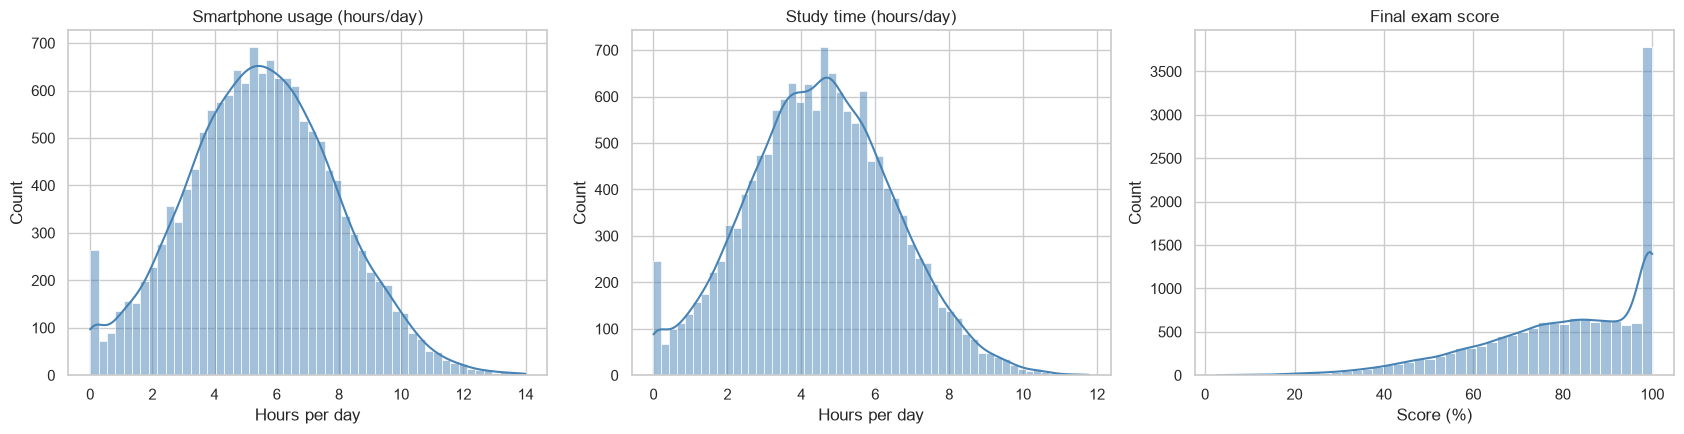

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_specs = [
    (screen_col, "Smartphone usage (hours/day)", "Hours per day"),
    (study_col, "Study time (hours/day)", "Hours per day"),
    (score_col, "Final exam score", "Score (%)")
]
for ax, (col, title, xlabel) in zip(axes, plot_specs):
    sns.histplot(data=analysis, x=col, kde=True, color="steelblue", ax=ax)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
plt.tight_layout()
plt.show()

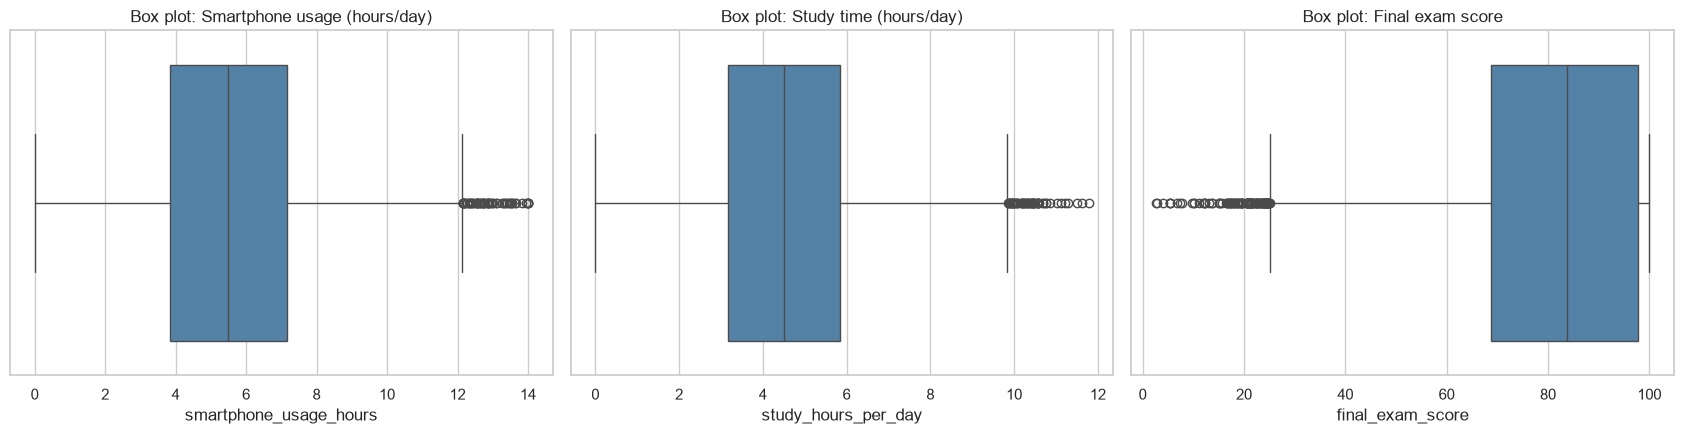

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (col, title, _) in zip(axes, plot_specs):
    sns.boxplot(data=analysis, x=col, color="steelblue", ax=ax)
    ax.set_title(f"Box plot: {title}")
plt.tight_layout()
plt.show()

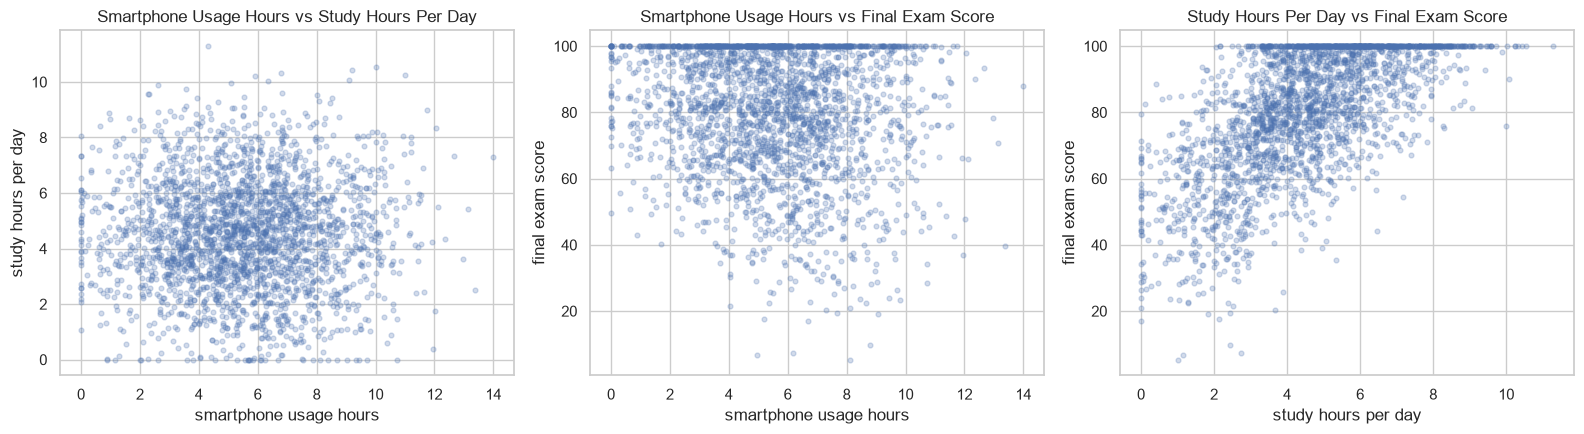

In [7]:
# Pairwise scatter plots among the three primary variables (sampled for readability)
pair_sample = analysis[core_cols].sample(min(2500, len(analysis)), random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
pairs = [(screen_col, study_col), (screen_col, score_col), (study_col, score_col)]
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(pair_sample[x], pair_sample[y], alpha=0.25, s=12)
    ax.set_xlabel(x.replace("_", " "))
    ax.set_ylabel(y.replace("_", " "))
    ax.set_title(f"{x.replace('_', ' ').title()} vs {y.replace('_', ' ').title()}")
plt.tight_layout()
plt.show()


## 5. Distribution and normality checks

Histograms and Q–Q plots help assess whether each variable resembles a normal distribution. With a large sample, formal normality tests can flag tiny deviations that have little practical importance. For regression, the normality assumption concerns **model residuals** more directly than it concerns each predictor.

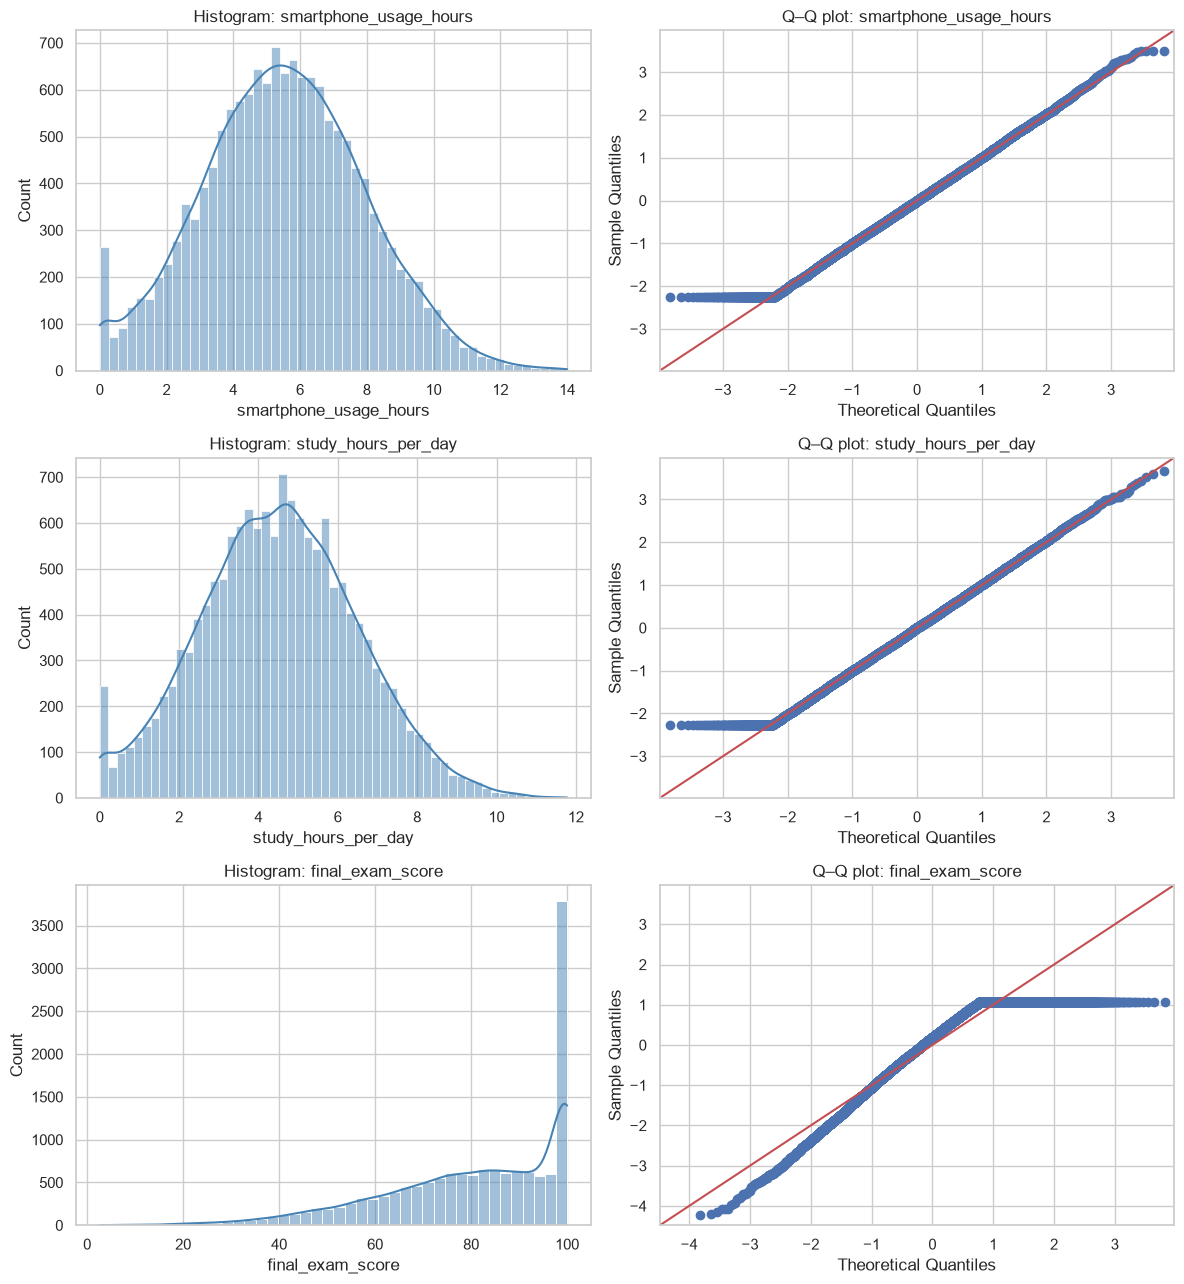

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(12, 13))
for i, col in enumerate(core_cols):
    sns.histplot(analysis[col], kde=True, color="steelblue", ax=axes[i, 0])
    axes[i, 0].set_title(f"Histogram: {col}")
    sm.qqplot(analysis[col], line="45", fit=True, ax=axes[i, 1])
    axes[i, 1].set_title(f"Q–Q plot: {col}")
plt.tight_layout()
plt.show()

In [9]:
# Shapiro-Wilk is not practical for very large samples (and can reject tiny deviations).
# Use a reproducible sample of at most 5,000 observations as a diagnostic, alongside plots.
rng = np.random.default_rng(42)
normality_rows = []
for col in core_cols:
    values = analysis[col].dropna().to_numpy()
    sample = rng.choice(values, size=min(5000, len(values)), replace=False)
    stat, p_value = stats.shapiro(sample)
    normality_rows.append({
        "variable": col,
        "sample_size_tested": len(sample),
        "Shapiro_W": stat,
        "p_value": p_value,
        "reject_normality_at_0.05": p_value < 0.05
    })
display(pd.DataFrame(normality_rows).round(5))
print("Interpret formal tests together with histograms and Q–Q plots, not in isolation.")

,variable,sample_size_tested,Shapiro_W,p_value,reject_normality_at_0.05
0,smartphone_usage_hours,5000,0.9968,0.0000,True
1,study_hours_per_day,5000,0.9972,0.0000,True
2,final_exam_score,5000,0.9032,0.0000,True


Interpret formal tests together with histograms and Q–Q plots, not in isolation.


## 6. Pearson correlation analysis

,smartphone_usage_hours,study_hours_per_day,final_exam_score
smartphone_usage_hours,1.0000,0.0011,-0.1424
study_hours_per_day,0.0011,1.0000,0.6440
final_exam_score,-0.1424,0.6440,1.0000


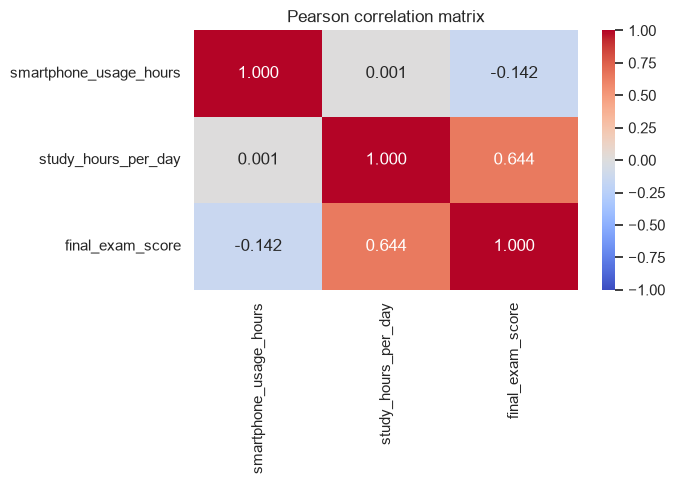

In [10]:
corr_matrix = analysis[core_cols].corr(method="pearson")
display(corr_matrix.round(4))

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Pearson correlation matrix")
plt.tight_layout()
plt.show()

In [11]:
def pearson_result(data, x, y):
    r, p = stats.pearsonr(data[x], data[y])
    n = len(data[[x, y]].dropna())
    # Fisher z approximate 95% confidence interval for Pearson r
    if n > 3 and abs(r) < 1:
        z = np.arctanh(r)
        se = 1 / np.sqrt(n - 3)
        ci_low, ci_high = np.tanh([z - 1.96 * se, z + 1.96 * se])
    else:
        ci_low, ci_high = np.nan, np.nan
    return {"x": x, "y": y, "n": n, "pearson_r": r,
            "p_value": p, "95% CI lower": ci_low, "95% CI upper": ci_high}

corr_results = pd.DataFrame([
    pearson_result(analysis, screen_col, score_col),
    pearson_result(analysis, study_col, score_col),
    pearson_result(analysis, screen_col, study_col),
])
display(corr_results.round(6))

for _, row in corr_results.iterrows():
    direction = "positive" if row["pearson_r"] > 0 else "negative" if row["pearson_r"] < 0 else "approximately zero"
    strength = abs(row["pearson_r"])
    magnitude = "very weak" if strength < .2 else "weak" if strength < .4 else "moderate" if strength < .6 else "strong"
    sig = "statistically significant" if row["p_value"] < 0.05 else "not statistically significant"
    print(f"{row['x']} vs {row['y']}: {magnitude} {direction} association "
          f"(r={row['pearson_r']:.3f}, p={row['p_value']:.4g}; {sig} at α=0.05).")

,x,y,n,pearson_r,p_value,95% CI lower,95% CI upper
0,smartphone_usage_hours,final_exam_score,15000,-0.1424,0.0000,-0.1580,-0.1266
1,study_hours_per_day,final_exam_score,15000,0.6440,0.0000,0.6345,0.6533
2,smartphone_usage_hours,study_hours_per_day,15000,0.0011,0.8972,-0.0149,0.0171


smartphone_usage_hours vs final_exam_score: very weak negative association (r=-0.142, p=9.565e-69; statistically significant at α=0.05).
study_hours_per_day vs final_exam_score: strong positive association (r=0.644, p=0; statistically significant at α=0.05).
smartphone_usage_hours vs study_hours_per_day: very weak positive association (r=0.001, p=0.8972; not statistically significant at α=0.05).


### How to interpret correlation
- \(r\) ranges from −1 to +1.
- A positive \(r\) means the variables tend to increase together; a negative \(r\) means one tends to decrease as the other increases.
- The p-value evaluates evidence against a zero population correlation; it does **not** measure the size or importance of the relationship.
- Correlation does not prove that screen time causes a change in marks.

## 7. Scatter plots with fitted trend lines

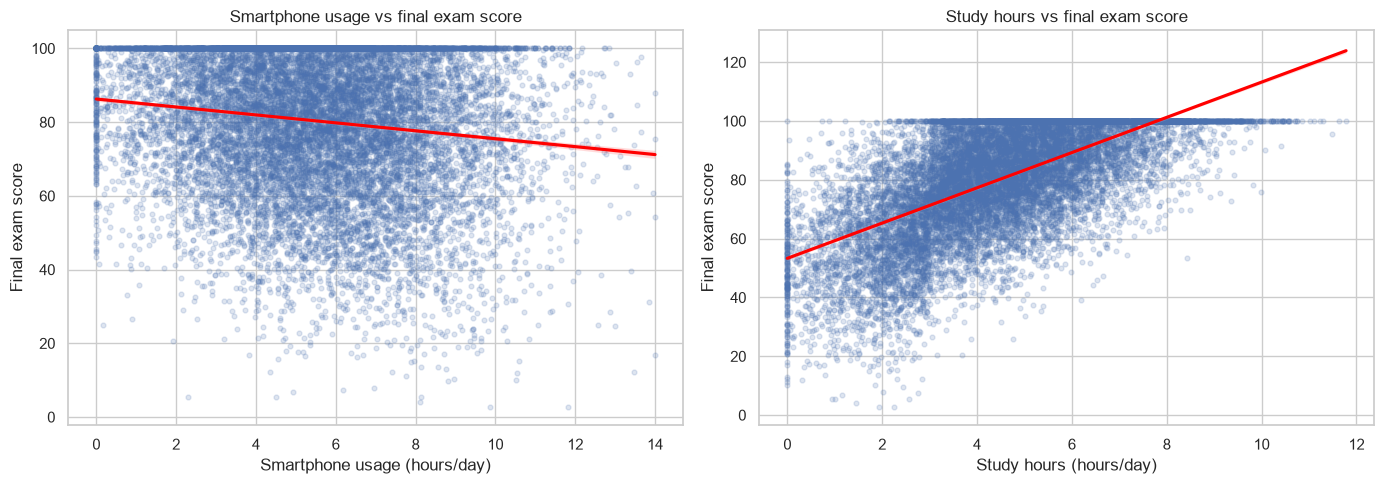

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=analysis, x=screen_col, y=score_col,
            scatter_kws={"alpha": 0.18, "s": 12}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title("Smartphone usage vs final exam score")
axes[0].set_xlabel("Smartphone usage (hours/day)")
axes[0].set_ylabel("Final exam score")

sns.regplot(data=analysis, x=study_col, y=score_col,
            scatter_kws={"alpha": 0.18, "s": 12}, line_kws={"color": "red"}, ax=axes[1])
axes[1].set_title("Study hours vs final exam score")
axes[1].set_xlabel("Study hours (hours/day)")
axes[1].set_ylabel("Final exam score")
plt.tight_layout()
plt.show()

## 8. Multiple linear regression

The primary model follows the presentation:

\[
\text{Exam Score} = \beta_0 + \beta_1(\text{Study Hours}) +
\beta_2(\text{Smartphone Usage}) + \epsilon
\]

- \(\beta_0\): predicted score when both predictors equal zero (may not be substantively meaningful).
- \(\beta_1\): expected score difference for one additional study hour per day, holding smartphone use constant.
- \(\beta_2\): expected score difference for one additional smartphone-use hour per day, holding study hours constant.

In [13]:
model = smf.ols(
    formula=f"{score_col} ~ {study_col} + {screen_col}",
    data=analysis
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       final_exam_score   R-squared:                       0.435
Model:                            OLS   Adj. R-squared:                  0.435
Method:                 Least Squares   F-statistic:                     5778.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:24:19   Log-Likelihood:                -60712.
No. Observations:               15000   AIC:                         1.214e+05
Df Residuals:                   14997   BIC:                         1.215e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 59

In [15]:
# Compact coefficient table with confidence intervals
ci = model.conf_int()
coef_table = pd.DataFrame({
    "coefficient": model.params,
    "std_error": model.bse,
    "t_statistic": model.tvalues,
    "p_value": model.pvalues,
    "CI_95_lower": ci[0],
    "CI_95_upper": ci[1]
})
display(coef_table.round(5))

metrics = pd.DataFrame({
    "metric": ["Observations", "R-squared", "Adjusted R-squared", "F-statistic", "Model F-test p-value"],
    "value": [int(model.nobs), model.rsquared, model.rsquared_adj, model.fvalue, model.f_pvalue]
})
display(metrics.round(5))

print("\\nRegression interpretation:")
for term in [study_col, screen_col]:
    b = model.params[term]
    p = model.pvalues[term]
    sig = "significant" if p < 0.05 else "not statistically significant"
    print(f"Holding the other predictor constant, a 1-hour/day increase in {term} "
          f"is associated with an estimated {b:.3f}-point change in exam score "
          f"(p={p:.4g}; {sig} at α=0.05).")
print(f"The model explains {model.rsquared*100:.2f}% of the observed variation in exam scores (R²).")

,coefficient,std_error,t_statistic,p_value,CI_95_lower,CI_95_upper
Intercept,59.2551,0.3798,156.0013,0.0000,58.5106,59.9996
study_hours_per_day,5.9942,0.0571,104.9664,0.0000,5.8822,6.1061
smartphone_usage_hours,-1.0818,0.0464,-23.3080,0.0000,-1.1727,-0.9908


,metric,value
0,Observations,"15,000.0000"
1,R-squared,0.4352
2,Adjusted R-squared,0.4351
3,F-statistic,"5,778.0246"
4,Model F-test p-value,0.0000


\nRegression interpretation:
Holding the other predictor constant, a 1-hour/day increase in study_hours_per_day is associated with an estimated 5.994-point change in exam score (p=0; significant at α=0.05).
Holding the other predictor constant, a 1-hour/day increase in smartphone_usage_hours is associated with an estimated -1.082-point change in exam score (p=4.572e-118; significant at α=0.05).
The model explains 43.52% of the observed variation in exam scores (R²).


## 9. Regression diagnostics

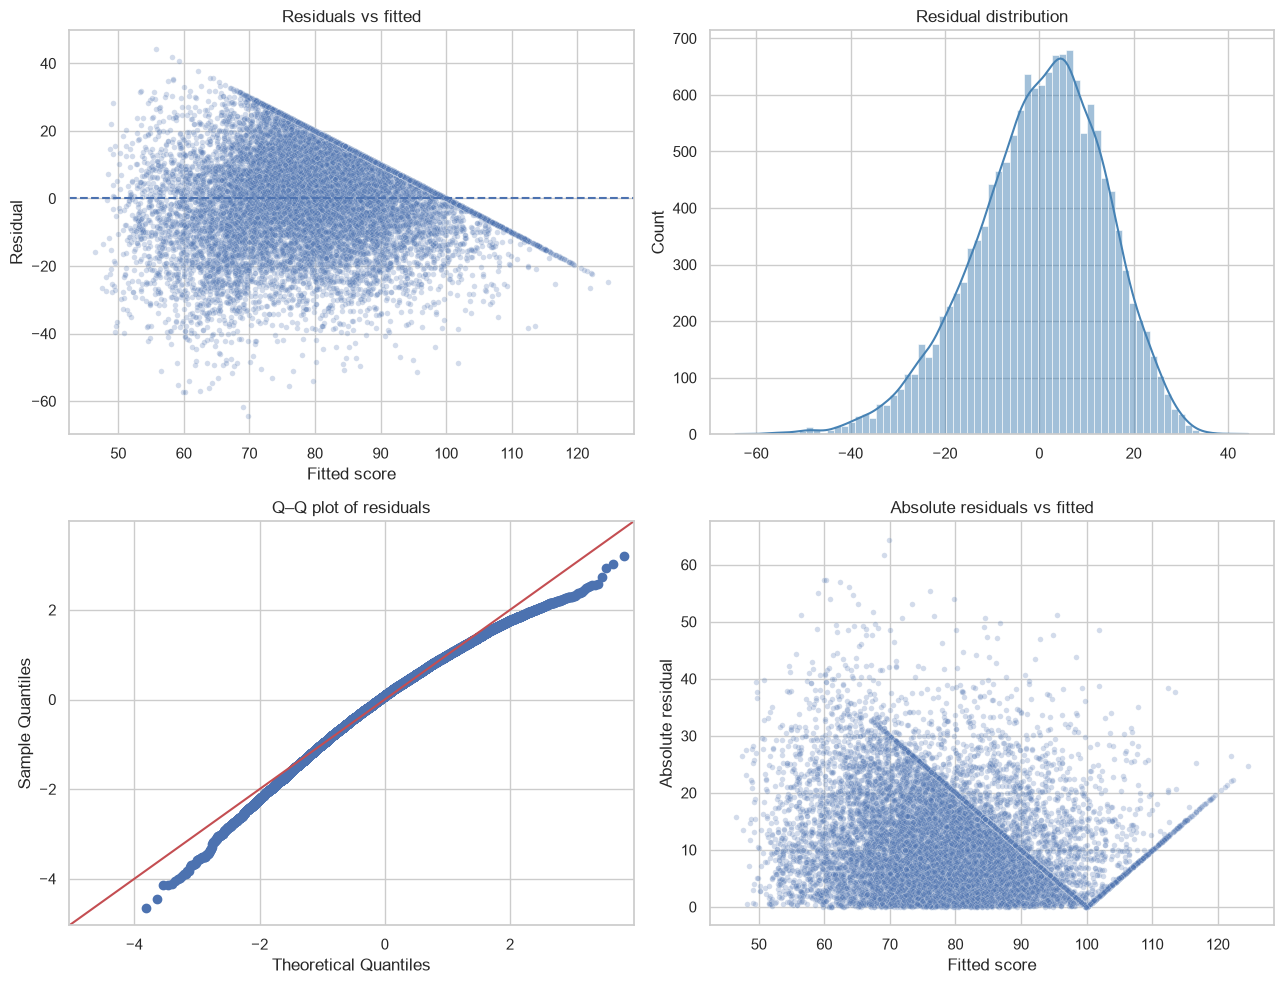

In [16]:
fitted = model.fittedvalues
residuals = model.resid

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
sns.scatterplot(x=fitted, y=residuals, alpha=0.25, s=16, ax=axes[0, 0])
axes[0, 0].axhline(0, linestyle="--")
axes[0, 0].set_title("Residuals vs fitted")
axes[0, 0].set_xlabel("Fitted score")
axes[0, 0].set_ylabel("Residual")

sns.histplot(residuals, kde=True, color="steelblue", ax=axes[0, 1])
axes[0, 1].set_title("Residual distribution")

sm.qqplot(residuals, line="45", fit=True, ax=axes[1, 0])
axes[1, 0].set_title("Q–Q plot of residuals")

sns.scatterplot(x=fitted, y=np.abs(residuals), alpha=0.25, s=16, ax=axes[1, 1])
axes[1, 1].set_title("Absolute residuals vs fitted")
axes[1, 1].set_xlabel("Fitted score")
axes[1, 1].set_ylabel("Absolute residual")
plt.tight_layout()
plt.show()

In [17]:
# Variance Inflation Factor (VIF) for the two predictors
X = analysis[[study_col, screen_col]].copy()
X = sm.add_constant(X)
vif_table = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
display(vif_table.round(4))

# Breusch-Pagan test for heteroscedasticity
bp_lm, bp_lm_p, bp_f, bp_f_p = sm.stats.diagnostic.het_breuschpagan(residuals, model.model.exog)
print(f"Breusch–Pagan LM p-value: {bp_lm_p:.5g}")
print("A small p-value suggests non-constant residual variance; consider robust standard errors.")

,variable,VIF
0,const,1.0000
1,study_hours_per_day,1.0000
2,smartphone_usage_hours,1.0000


Breusch–Pagan LM p-value: 1.4517e-158
A small p-value suggests non-constant residual variance; consider robust standard errors.


### Optional: heteroscedasticity-robust standard errors

In [18]:
robust_model = model.get_robustcov_results(cov_type="HC3")
robust_table = pd.DataFrame({
    "coefficient": model.params,
    "robust_std_error_HC3": robust_model.bse,
    "robust_p_value_HC3": robust_model.pvalues,
    "robust_CI_95_lower": robust_model.conf_int()[:, 0],
    "robust_CI_95_upper": robust_model.conf_int()[:, 1],
}, index=model.params.index)
display(robust_table.round(5))

,coefficient,robust_std_error_HC3,robust_p_value_HC3,robust_CI_95_lower,robust_CI_95_upper
Intercept,59.2551,0.3906,0.0000,58.4895,60.0207
study_hours_per_day,5.9942,0.0580,0.0000,5.8805,6.1079
smartphone_usage_hours,-1.0818,0.0469,0.0000,-1.1737,-0.9899


## 10. High vs low smartphone-use groups: Welch's t-test

To make a transparent two-group comparison, this notebook splits students at the **median smartphone-use value**. Welch's independent-samples t-test does not require equal group variances. The split is a descriptive choice, not a clinical or universally meaningful threshold.

In [19]:
median_screen = analysis[screen_col].median()
group_low = analysis.loc[analysis[screen_col] <= median_screen, score_col]
group_high = analysis.loc[analysis[screen_col] > median_screen, score_col]

t_stat, p_value = stats.ttest_ind(group_high, group_low, equal_var=False, nan_policy="omit")

# Welch confidence interval for difference in means (high - low)
n1, n0 = len(group_high), len(group_low)
m1, m0 = group_high.mean(), group_low.mean()
v1, v0 = group_high.var(ddof=1), group_low.var(ddof=1)
diff = m1 - m0
se_diff = np.sqrt(v1/n1 + v0/n0)
df_welch = (v1/n1 + v0/n0)**2 / ((v1/n1)**2/(n1-1) + (v0/n0)**2/(n0-1))
crit = stats.t.ppf(0.975, df_welch)
ci_low, ci_high = diff - crit*se_diff, diff + crit*se_diff

# Cohen's d using pooled standard deviation as a descriptive effect size
pooled_sd = np.sqrt(((n1-1)*v1 + (n0-1)*v0) / (n1+n0-2))
cohens_d = diff / pooled_sd

group_summary = pd.DataFrame({
    "group": ["Lower use (≤ median)", "Higher use (> median)"],
    "n": [n0, n1],
    "mean_exam_score": [m0, m1],
    "sd_exam_score": [np.sqrt(v0), np.sqrt(v1)]
})
display(group_summary.round(4))
print(f"Median smartphone use: {median_screen:.3f} hours/day")
print(f"Difference in means (higher − lower): {diff:.3f} points")
print(f"Welch t({df_welch:.1f}) = {t_stat:.3f}, p = {p_value:.5g}")
print(f"95% CI for mean difference: [{ci_low:.3f}, {ci_high:.3f}]")
print(f"Cohen's d = {cohens_d:.3f}")

,group,n,mean_exam_score,sd_exam_score
0,Lower use (≤ median),7507,82.4475,17.0815
1,Higher use (> median),7493,78.2373,19.4716


Median smartphone use: 5.480 hours/day
Difference in means (higher − lower): -4.210 points
Welch t(14740.9) = -14.076, p = 1.0428e-44
95% CI for mean difference: [-4.796, -3.624]
Cohen's d = -0.230


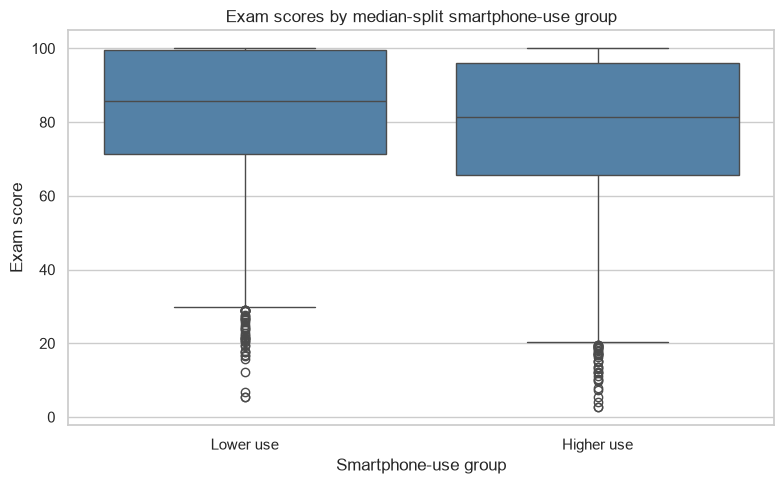

In [20]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=pd.DataFrame({
    "Exam score": pd.concat([group_low, group_high], ignore_index=True),
    "Smartphone-use group": (["Lower use"]*len(group_low)) + (["Higher use"]*len(group_high))
}), x="Smartphone-use group", y="Exam score", color="steelblue")
plt.title("Exam scores by median-split smartphone-use group")
plt.tight_layout()
plt.show()

## 11. IQR outlier sensitivity analysis

This section applies the 1.5 × IQR rule to the three primary variables together and removes a row if **any** of them falls outside its variable's IQR bounds. It reports the actual number retained in this CSV. Compare the main correlations and regression with this filtered sample; do not assume outlier removal automatically improves validity.

In [21]:
def iqr_filter(data, columns, multiplier=1.5):
    keep = pd.Series(True, index=data.index)
    bounds = {}
    for col in columns:
        q1 = data[col].quantile(0.25)
        q3 = data[col].quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - multiplier*iqr, q3 + multiplier*iqr
        bounds[col] = {"Q1": q1, "Q3": q3, "IQR": iqr, "lower_bound": low, "upper_bound": high}
        keep &= data[col].between(low, high)
    return data.loc[keep].copy(), pd.DataFrame(bounds).T, keep

clean_iqr, iqr_bounds, keep_mask = iqr_filter(analysis, core_cols)
print(f"Valid rows before IQR filtering: {len(analysis):,}")
print(f"Rows retained after IQR filtering: {len(clean_iqr):,}")
print(f"Rows removed by IQR rule: {len(analysis)-len(clean_iqr):,}")
display(iqr_bounds.round(4))

Valid rows before IQR filtering: 15,000
Rows retained after IQR filtering: 14,784
Rows removed by IQR rule: 216


,Q1,Q3,IQR,lower_bound,upper_bound
smartphone_usage_hours,3.8300,7.1500,3.3200,-1.1500,12.1300
study_hours_per_day,3.1675,5.8400,2.6725,-0.8412,9.8487
final_exam_score,68.7300,97.8100,29.0800,25.1100,141.4300


In [ ]:
sensitivity_corr = pd.DataFrame([
    {"sample": "Full valid data", **pearson_result(analysis, screen_col, score_col)},
    {"sample": "IQR-filtered data", **pearson_result(clean_iqr, screen_col, score_col)}
])
display(sensitivity_corr[["sample", "n", "pearson_r", "p_value", "95% CI lower", "95% CI upper"]].round(6))

model_iqr = smf.ols(
    formula=f"{score_col} ~ {study_col} + {screen_col}",
    data=clean_iqr
).fit()
comparison = pd.DataFrame({
    "Full valid data": [len(analysis), model.params[study_col], model.params[screen_col], model.rsquared],
    "IQR-filtered data": [len(clean_iqr), model_iqr.params[study_col], model_iqr.params[screen_col], model_iqr.rsquared]
}, index=["N", "Study-hours coefficient", "Smartphone-use coefficient", "R-squared"])
display(comparison.round(5))

## 12. Optional exploratory analysis: other digital-life variables

The dataset also contains social media, gaming, streaming, sleep, attendance, assignment completion, and other variables. This optional section explores simple correlations with exam score. These are exploratory associations and may involve confounding or overlapping measures. Do not add smartphone, social media, gaming, and streaming hours into a single total unless the dataset codebook confirms they are mutually exclusive and measured consistently.

,correlation_with_exam_score
smartphone_usage_hours,-0.1424
gaming_hours,-0.0872
streaming_hours,-0.0337
caffeine_intake_cups,-0.0008
social_media_hours,0.0042
exercise_hours,0.0501
sleep_hours,0.0728
class_attendance_percent,0.1418
motivation_level,0.1560
assignment_completion_percent,0.2003


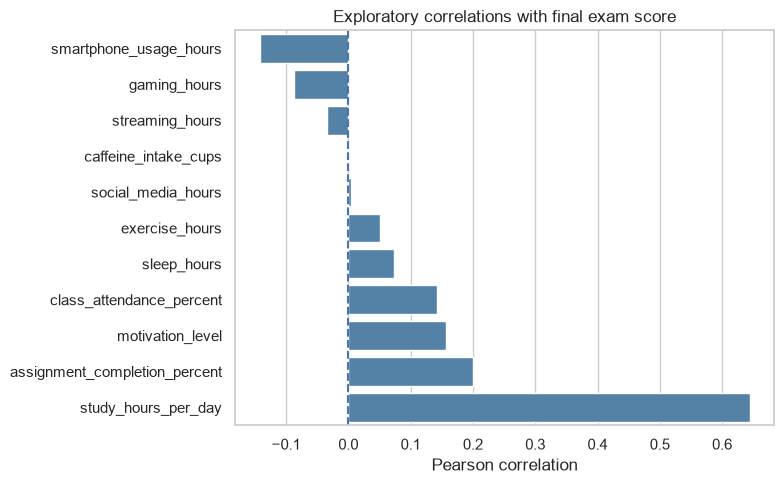

In [22]:
exploratory_cols = [
    c for c in [
        "smartphone_usage_hours", "social_media_hours", "gaming_hours",
        "streaming_hours", "study_hours_per_day", "sleep_hours",
        "exercise_hours", "class_attendance_percent",
        "assignment_completion_percent", "motivation_level",
        "caffeine_intake_cups"
    ] if c in analysis.columns
]
exploratory = analysis[exploratory_cols + [score_col]].copy()
for c in exploratory.columns:
    exploratory[c] = pd.to_numeric(exploratory[c], errors="coerce")

exploratory_corr = exploratory.corr(numeric_only=True)[score_col].drop(score_col).sort_values()
display(exploratory_corr.to_frame("correlation_with_exam_score"))

plt.figure(figsize=(8, max(5, 0.42*len(exploratory_corr))))
sns.barplot(x=exploratory_corr.values, y=exploratory_corr.index, color="steelblue")
plt.axvline(0, linestyle="--")
plt.title("Exploratory correlations with final exam score")
plt.xlabel("Pearson correlation")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 13. Automatically generated results summary

In [23]:
r_screen = stats.pearsonr(analysis[screen_col], analysis[score_col])
r_study = stats.pearsonr(analysis[study_col], analysis[score_col])
b_screen = model.params[screen_col]
p_screen = model.pvalues[screen_col]
b_study = model.params[study_col]
p_study = model.pvalues[study_col]

decision = "reject H₀" if r_screen.pvalue < 0.05 else "fail to reject H₀"
summary = f"""
## Results summary (generated from the uploaded CSV)

- **Sample size:** {len(analysis):,} records with complete values for the three main variables.
- **Smartphone usage and exam score:** Pearson's r = {r_screen.statistic:.3f}, p = {r_screen.pvalue:.4g}. At α = 0.05, **{decision}** for the zero-correlation hypothesis.
- **Study hours and exam score:** Pearson's r = {r_study.statistic:.3f}, p = {r_study.pvalue:.4g}.
- **Regression fit:** R² = {model.rsquared:.3f}; adjusted R² = {model.rsquared_adj:.3f}.
- **Study-hours coefficient:** {b_study:.3f} score points per additional study hour/day, controlling for smartphone use (p = {p_study:.4g}).
- **Smartphone-use coefficient:** {b_screen:.3f} score points per additional smartphone-use hour/day, controlling for study hours (p = {p_screen:.4g}).
- **IQR sensitivity sample:** {len(clean_iqr):,} records retained and {len(analysis)-len(clean_iqr):,} removed by the defined 1.5 × IQR rule.

### Draft interpretation

Use the values above to write a result paragraph, but interpret the effect sizes and confidence intervals—not just p-values. Since the data are observational, results show association rather than causation. Confirm how the dataset was collected and whether participants are specifically college students before making population-wide claims.
"""
display(Markdown(summary))



## Results summary (generated from the uploaded CSV)

- **Sample size:** 15,000 records with complete values for the three main variables.
- **Smartphone usage and exam score:** Pearson's r = -0.142, p = 9.565e-69. At α = 0.05, **reject H₀** for the zero-correlation hypothesis.
- **Study hours and exam score:** Pearson's r = 0.644, p = 0.
- **Regression fit:** R² = 0.435; adjusted R² = 0.435.
- **Study-hours coefficient:** 5.994 score points per additional study hour/day, controlling for smartphone use (p = 0).
- **Smartphone-use coefficient:** -1.082 score points per additional smartphone-use hour/day, controlling for study hours (p = 4.572e-118).
- **IQR sensitivity sample:** 14,784 records retained and 216 removed by the defined 1.5 × IQR rule.

### Draft interpretation

Use the values above to write a result paragraph, but interpret the effect sizes and confidence intervals—not just p-values. Since the data are observational, results show association rather than causation. Confirm how the dataset was collected and whether participants are specifically college students before making population-wide claims.


## 14. Report-writing checklist

Use the notebook output to write these report sections:

1. **Introduction:** Explain why screen use and study habits are relevant; state the research questions.
2. **Dataset and variables:** Cite the dataset source and document the meaning and units of the selected columns.
3. **Methodology:** Explain descriptive statistics, Pearson correlation, OLS multiple regression, Welch's t-test, α = 0.05, and the IQR sensitivity check.
4. **Results:** Insert the actual sample size, descriptive-statistics table, plots, correlation coefficients, p-values, regression coefficients, confidence intervals, and R².
5. **Discussion:** Explain direction, strength, statistical significance, practical size, and whether results align with your hypotheses.
6. **Limitations:** Note that observational data cannot prove causality; the dataset's sampling and representativeness must be verified; smartphone use may not equal total screen time; omitted factors may affect grades; and large samples can make small effects statistically significant.
7. **Conclusion:** Answer the research questions without claiming that screen time causes grades to change.

### Before submitting
- Verify the Kaggle dataset's official description, license, and data-generation/sampling process.
- Check the dataset's actual target population; do not claim the 15,000 rows represent college students unless supported by the source documentation.
- Replace any presentation figures (including the claimed cleaned sample size) with results reproduced by this notebook, or explain why a different cleaning rule was used.
- Include software/library versions if required by your instructor.